# Auditoría de datos del precio del petróleo

Este notebook examina archivos locales sin descargarlos, modificarlos, rellenarlos ni entrenar modelos. Las salidas se calculan al ejecutarlo; no se incluyen cifras copiadas como resultados.

**Corte fijo:** 04/11/2026. **Calendario de diagnóstico:** 04/01/2000–04/11/2026, lunes a viernes, incluidos festivos. La solicitud original empezó el 01/01/2000; el calendario de comparación comienza en la primera observación Brent del snapshot.

Ejecutar de arriba abajo con el entorno Poetry. Pandas y NumPy ya forman parte del entorno; para las gráficas y el kernel se requieren `matplotlib` e `ipykernel`. Si faltan, instalarlos antes con `poetry add --group dev matplotlib ipykernel` (no se ejecuta desde el notebook). Seleccionar ese entorno como kernel en VS Code/Jupyter.

Los snapshots están ignorados en Git. Un clon necesita los archivos originales indicados abajo; repetir una descarga actual no garantiza obtener los mismos datos históricos. Todas las fuentes se leen de una única carpeta creada por `scripts/download_all_data.py`; configurar BUNDLE en la primera celda. No se utilizan archivos de Descargas. No se requiere clave API para esta auditoría.


In [1]:
from pathlib import Path
import json, hashlib, zipfile, io
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists()), None)
if ROOT is None:
    raise RuntimeError('Abre el notebook dentro del repositorio')
# Pegar el nombre exacto impreso por download_all_data.py. No elegir "el último" automáticamente.
BUNDLE = ROOT / 'data/raw/20261106T142300_705279Z_all'
CORTE = pd.Timestamp('2026-11-04')
CALENDARIO = pd.bdate_range('2000-01-04', CORTE)
bundle_manifest = json.loads((BUNDLE / 'manifest.json').read_text(encoding='utf-8'))
assert bundle_manifest['schema'] == 'oil-audit-bundle-v1'
assert bundle_manifest['status'] == 'complete', 'Descarga unificada incompleta'
assert bundle_manifest['end'] == str(CORTE.date()), 'Corte distinto al de esta auditoría'
componentes = bundle_manifest['components']
for item in componentes.values():
    assert item['status'] == 'ok'
    if 'sha256' in item:
        assert hashlib.sha256((BUNDLE / item['path']).read_bytes()).hexdigest() == item['sha256']
RAW = BUNDLE / componentes['raw']['path']
ALFRED = {s: componentes[s]['path'] for s in
          ['DCOILBRENTEU', 'DCOILWTICO', 'DHHNGSP', 'VIXCLS', 'DEXUSEU', 'DEXCHUS', 'ECBDFR']}
OPEP = BUNDLE / componentes['opep']['path']
sha256 = lambda p: hashlib.sha256(p.read_bytes()).hexdigest()
print('Días de comparación:', len(CALENDARIO))


Días de comparación: 7002


## 1. Inventario y trazabilidad

El snapshot raw es obligatorio para el análisis principal. El manifiesto global debe indicar complete. No se sustituye una fuente por otra descarga automáticamente. Un hash coincidente acredita integridad respecto al manifiesto, no calidad económica.


In [2]:
manifest = json.loads((RAW / 'manifest.json').read_text(encoding='utf-8'))
assert manifest['status'] == 'complete', 'Snapshot principal incompleto'
fuentes, inventario = {}, []
for item in manifest['sources']:
    p = RAW / item['file']
    assert sha256(p) == item['sha256'], f'Hash distinto: {p.name}'
    df = pd.read_csv(p, index_col=0, parse_dates=True)
    fuentes[item['name']] = df
    inventario.append({'fuente': item['name'], 'archivo': p.name, 'filas': len(df),
                       'inicio': df.index.min(), 'fin': df.index.max(), 'sha256': sha256(p)})
display(pd.DataFrame(inventario))
original_path = BUNDLE / componentes['initial_csv']['path']
original = pd.read_csv(original_path, index_col=0, parse_dates=True)
print('CSV inicial (ya rellenado):', original.shape, 'SHA256:', sha256(original_path))


,fuente,archivo,filas,inicio,fin,sha256
0,brent,fred_brent.csv,7001,2000-01-04,2026-11-03,3a992abeb85fd4416de6c2f3bbc7f63226018e8055d8f5...
1,wti,fred_wti.csv,7001,2000-01-04,2026-11-03,9fe524bedd8c830382ad196a271a2fd09c2ab7d3842181...
2,gas_natural,fred_gas_natural.csv,6997,2000-01-10,2026-11-03,cfde0f2eabba0a240ad7de6f0533aa946c5c43d1655c0a...
3,tipo_bce,fred_tipo_bce.csv,9805,2000-01-01,2026-11-04,95e13a7602695d8d1b6e9640494ba51e3c0fab8d88d952...
4,usd_por_eur,fred_usd_por_eur.csv,7000,2000-01-03,2026-10-30,a2421fc8b5bfdeedd5e2f67ce5d36feaa6e6dd3fe7211f...
5,cny_por_usd,fred_cny_por_usd.csv,7000,2000-01-03,2026-10-30,fd2df5ecfb9155e1e1a2e6286f42cec35195ee0ae6d603...
6,vix,fred_vix.csv,7003,2000-01-03,2026-11-04,1409faa24bf4f96edc15c379a8bb78085330f836f49cdf...
7,brent_fut,yahoo_brent_fut.csv,4797,2007-07-30,2026-11-04,c909e4f53b31d09daa9455633ff87d738d9d0e0891ead0...
8,wti_fut,yahoo_wti_fut.csv,6579,2000-08-23,2026-11-04,58db5089b17883d0b6b8889e6b0c8c62a4d7aad0f447d8...
9,cobre,yahoo_cobre.csv,6575,2000-08-30,2026-11-04,2734dd39c9e583b8c2f307e214f5b02fcf2e5dd51a3527...


CSV inicial (ya rellenado): (7002, 20) SHA256: a477e2abef785a1c985d5df50580641f9884fcdf6f7ca50724118da395697e75


## 2. Estructura, cobertura y ausencias

Se distinguen filas con valor ausente de fechas que la fuente no incluye. La comparación se alinea en memoria al calendario común; no guarda ni rellena datos. Los huecos no se atribuyen automáticamente a festivos. Las diferencias con el CSV inicial no bastan para identificar revisiones o causas.


In [3]:
resumen = []
for nombre, df in fuentes.items():
    for columna in df:
        s = df[columna]
        valido = s.dropna()
        fila = dict(fuente=nombre, columna=columna, duplicados=int(df.index.duplicated().sum()),
                    ordenado=df.index.is_monotonic_increasing,
                    fines_semana=int((df.index.day_of_week >= 5).sum()),
                    nulos_en_filas=int(s.isna().sum()), inicio_valido=valido.index.min(),
                    fin_valido=valido.index.max(), minimo=s.min(), maximo=s.max())
        if not df.index.has_duplicates:
            alineada = s.reindex(CALENDARIO)
            posterior = alineada.loc[valido.index.min():] if len(valido) else alineada
            faltante = posterior.isna()
            rachas = faltante.groupby((~faltante).cumsum()).sum()
            fila.update(ausentes_calendario=int(alineada.isna().sum()),
                        ausentes_tras_inicio=int(faltante.sum()),
                        mayor_racha=int(rachas.max()) if len(rachas) else 0)
        resumen.append(fila)
auditoria = pd.DataFrame(resumen)
display(auditoria)
assert not auditoria['duplicados'].any(), 'Resolver duplicados antes de alinear'
panel = pd.concat(list(fuentes.values()), axis=1, sort=True).reindex(CALENDARIO)
display(pd.DataFrame({'nulos_raw': panel.isna().sum(),
                      'nulos_csv_inicial': original.reindex(CALENDARIO).isna().sum()}))


,fuente,columna,duplicados,ordenado,fines_semana,nulos_en_filas,inicio_valido,fin_valido,minimo,maximo,ausentes_calendario,ausentes_tras_inicio,mayor_racha
0,brent,brent,0,True,0,500,2000-01-04,2026-11-03,9.120000,1.439500e+02,501,501,7
1,wti,wti,0,True,0,649,2000-01-04,2026-11-03,-36.980000,1.453100e+02,650,650,5
2,gas_natural,gas_natural,0,True,0,1570,2000-01-10,2026-11-03,1.210000,3.072000e+01,1575,1571,28
3,tipo_bce,tipo_bce,0,True,2802,0,2000-01-01,2026-11-04,-0.500000,4.000000e+00,0,0,0
4,usd_por_eur,usd_por_eur,0,True,0,273,2000-01-03,2026-10-30,0.827000,1.601000e+00,276,276,3
5,cny_por_usd,cny_por_usd,0,True,0,272,2000-01-03,2026-10-30,6.040200,8.280000e+00,275,275,3
6,vix,vix,0,True,0,218,2000-01-03,2026-11-04,9.140000,8.269000e+01,218,218,4
7,brent_fut,brent_fut_Open,0,True,0,0,2007-07-30,2026-11-04,19.559999,1.460800e+02,2205,231,12
8,brent_fut,brent_fut_High,0,True,0,0,2007-07-30,2026-11-04,21.270000,1.474300e+02,2205,231,12
9,brent_fut,brent_fut_Low,0,True,0,0,2007-07-30,2026-11-04,16.000000,1.442700e+02,2205,231,12


,nulos_raw,nulos_csv_inicial
brent,501,0
brent_fut_Close,2205,1974
brent_fut_High,2205,1974
brent_fut_Low,2205,1974
brent_fut_Open,2205,1974
brent_fut_Volume,2205,1974
cny_por_usd,275,0
cobre,427,171
gas_natural,1575,4
indice_dolar,223,0


## 3. Gráficos y extremos

La figura representa cada variable en su propia escala. No es una comparación de magnitudes entre unidades distintas. Se conservan precios negativos y otros extremos; no se decide su eliminación por su tamaño. El porcentaje anual de ausencias describe observaciones, no disponibilidad al predecir.


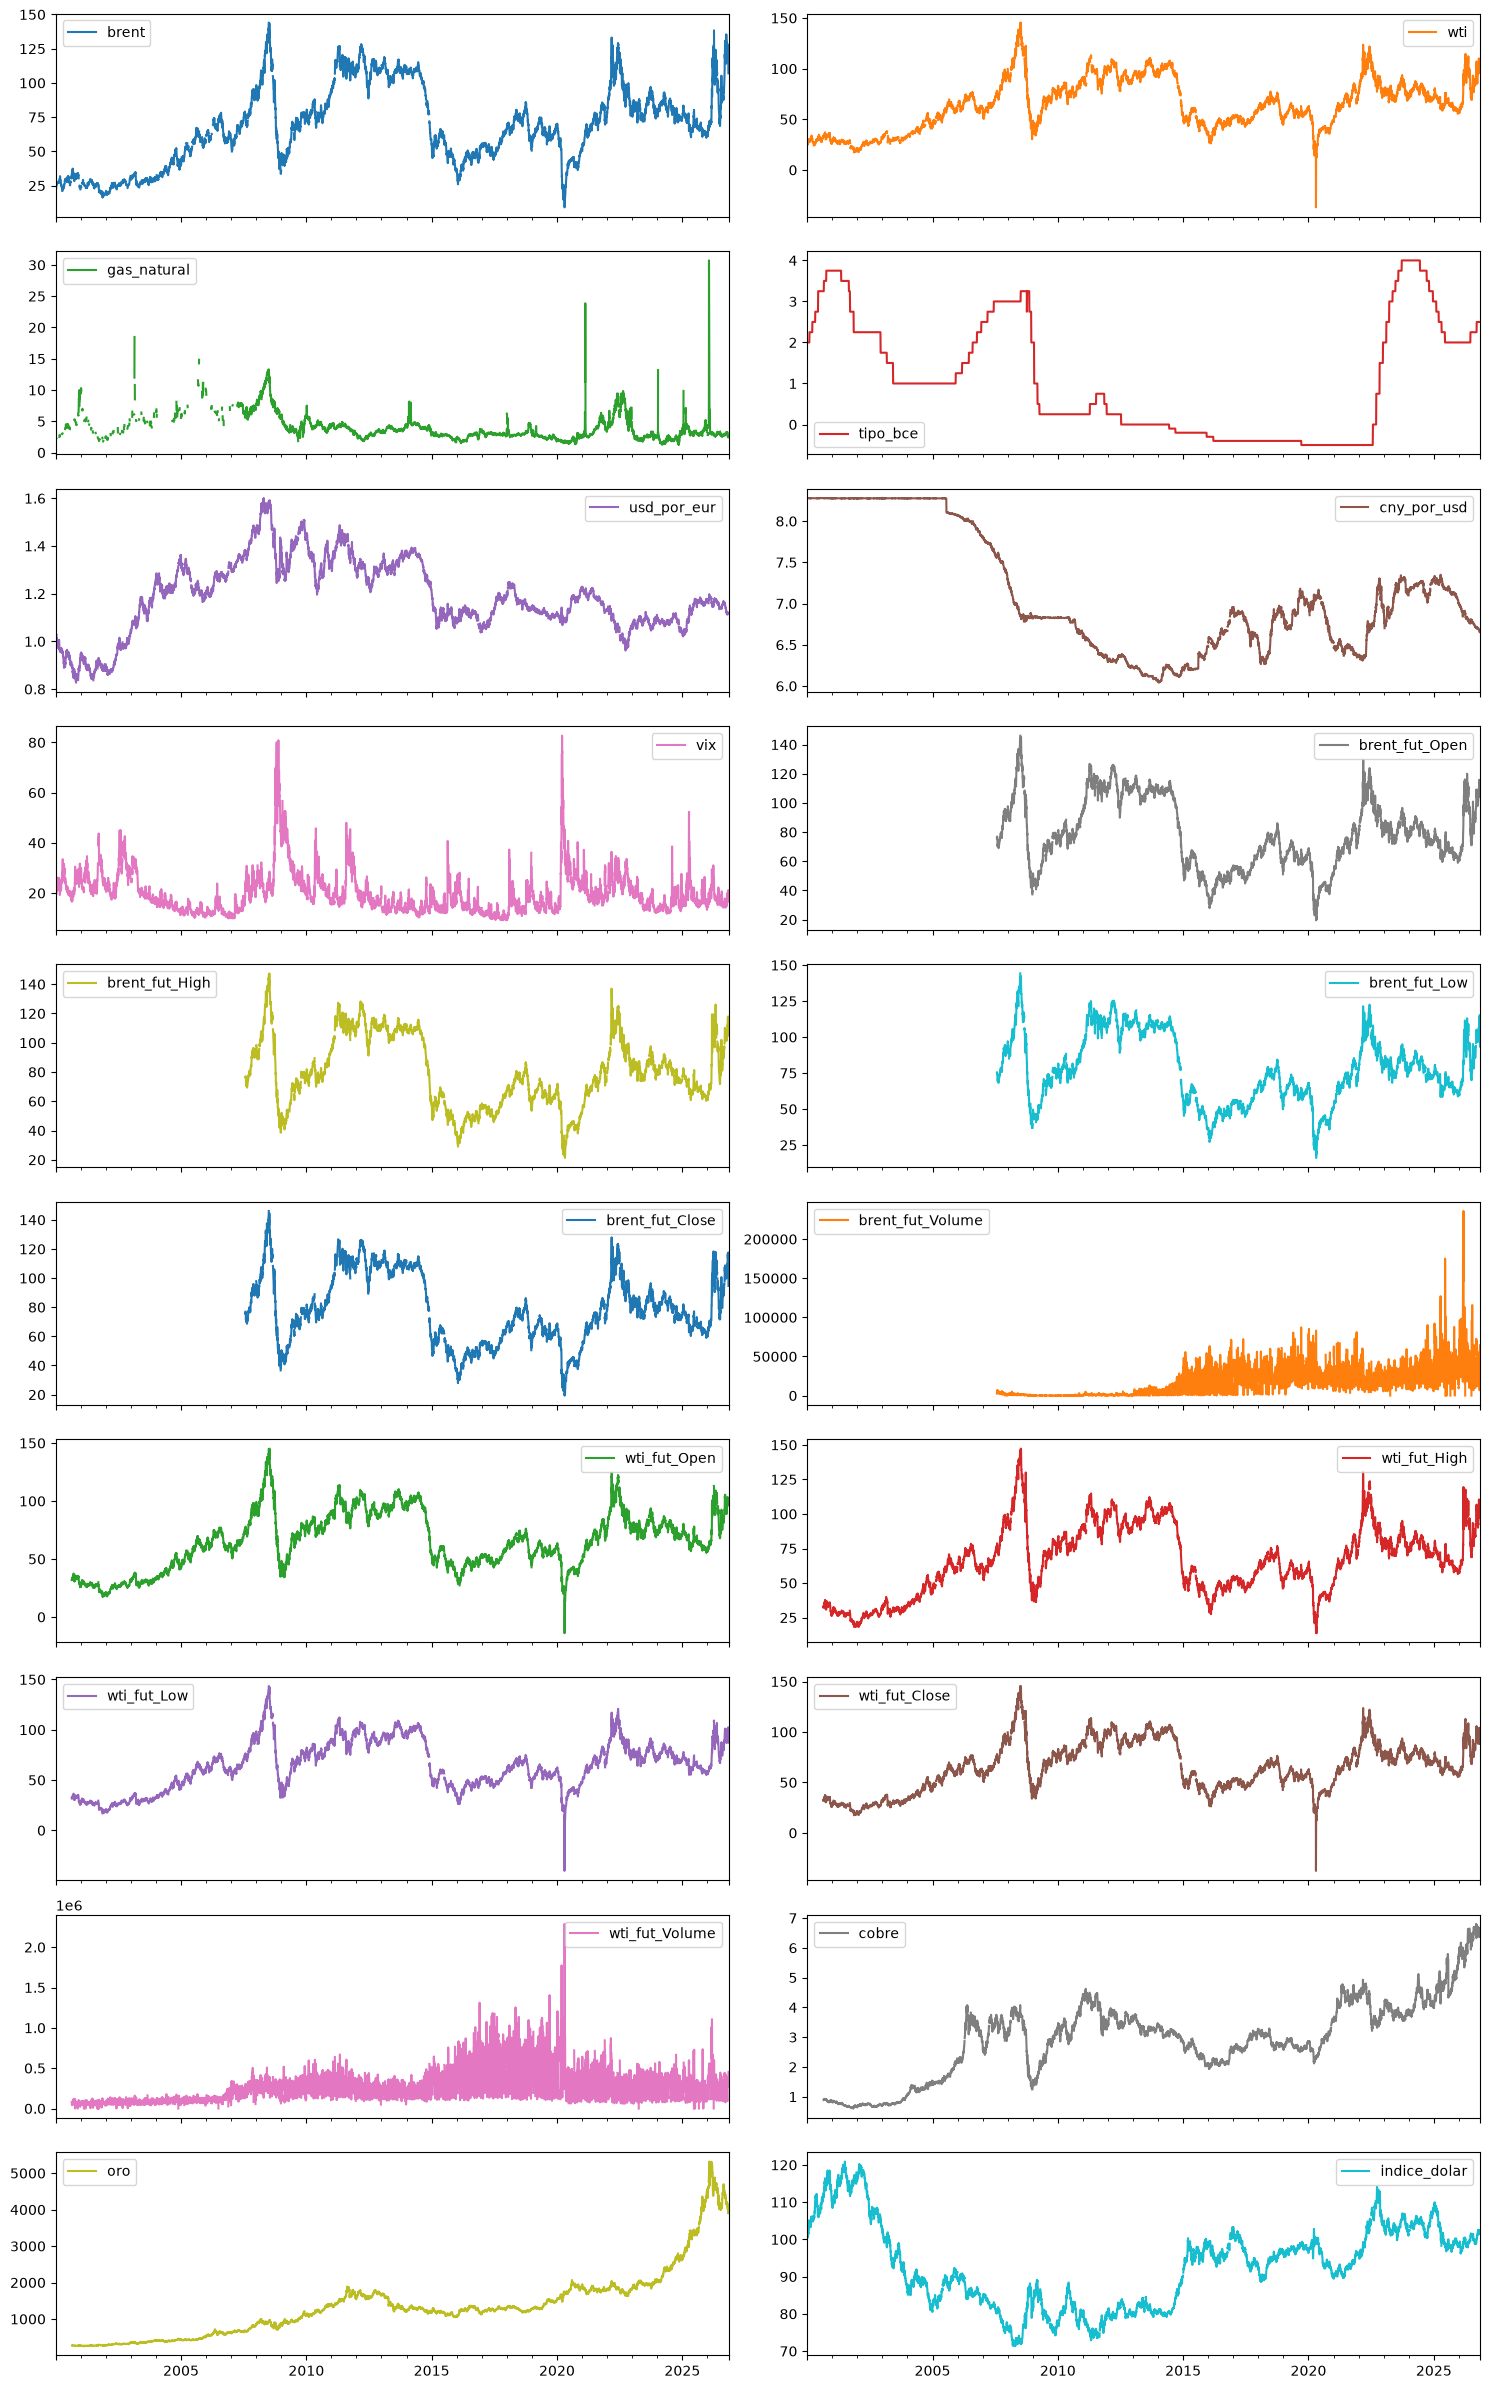

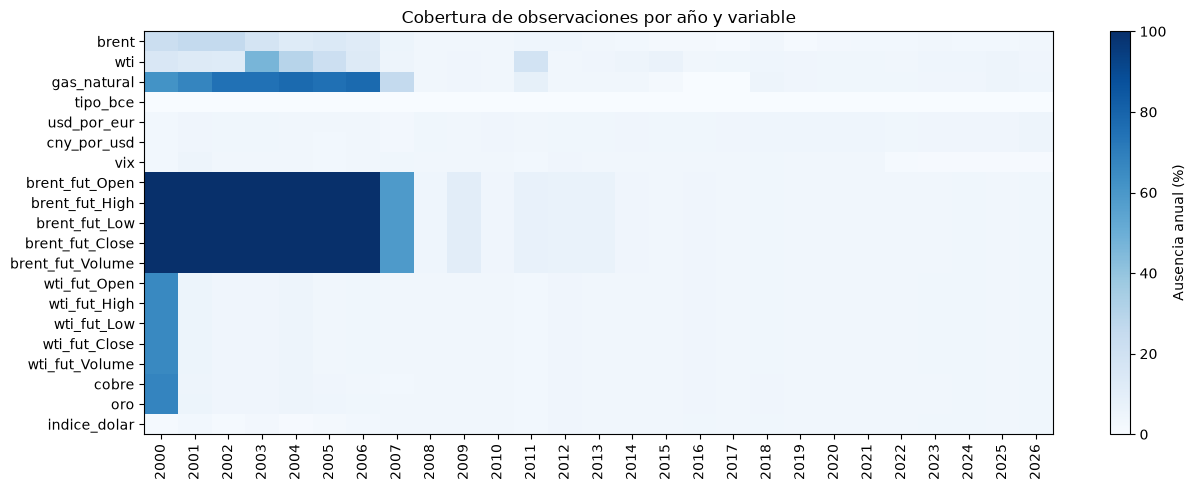

,minimos
2020-04-21,9.12
2020-04-22,13.77
2020-03-31,14.85
2020-04-01,14.97
2020-04-23,15.06


,maximos
2008-07-03,143.95
2008-07-11,143.68
2008-07-14,142.43
2008-07-02,141.24
2008-07-01,140.67


,minimos
2020-04-20,-36.98
2020-04-21,8.91
2020-04-27,12.17
2020-04-28,12.40
2020-04-22,13.64


,maximos
2008-07-03,145.31
2008-07-14,145.16
2008-07-11,144.96
2008-07-02,143.74
2008-07-10,141.47


In [4]:
import matplotlib.pyplot as plt
panel.plot(subplots=True, layout=(-1, 2), figsize=(15, 24), legend=True, sharex=True)
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(13, 5))
anual = panel.isna().groupby(panel.index.year).mean().mul(100).T
im = ax.imshow(anual, aspect='auto', vmin=0, vmax=100, cmap='Blues')
ax.set_yticks(range(len(anual.index)), labels=anual.index)
ax.set_xticks(range(len(anual.columns)), labels=anual.columns, rotation=90)
fig.colorbar(im, ax=ax, label='Ausencia anual (%)')
ax.set_title('Cobertura de observaciones por año y variable')
plt.tight_layout()
plt.show()
for nombre in ['brent', 'wti']:
    s = panel[nombre].dropna()
    display(pd.DataFrame({'minimos': s.nsmallest(5)}))
    display(pd.DataFrame({'maximos': s.nlargest(5)}))


## 4. Disponibilidad histórica ALFRED

Fecha de observación, fecha de versión y hora de publicación son conceptos diferentes. Para reproducir el diagnóstico usamos el intervalo vigente al **día natural anterior**, la observación anterior al origen y edad máxima de cinco días lunes-viernes. Antes del primer intervalo: **desconocido**, no ausencia real del precio.

Para ECBDFR se cuenta solamente si existe un valor publicado, sin caducidad. Ese resultado no determina el tipo efectivo en cada mañana de cambio: el criterio aprobado usará la tabla oficial BCE.

Los bloques JSON pueden recortar intervalos; no se cuentan filas como versiones únicas. Las siete series se leen de respuestas JSON de la API; ya no se utilizan ZIP manuales. Este diagnóstico no aplica todavía la reconstrucción aproximada desde 2000 recomendada para el experimento principal; los retrasos FRED de ese protocolo siguen pendientes.


In [5]:
intervalos, evidencia, pendientes = {}, [], []
for serie, carpeta in ALFRED.items():
    p = BUNDLE / carpeta
    if not (p / 'manifest.json').exists():
        pendientes.append(serie)
        continue
    m = json.loads((p / 'manifest.json').read_text(encoding='utf-8'))
    assert m['status'] == 'complete', f'{serie}: descarga incompleta'
    registros = []
    for page in m['pages']:
        f = p / page['file']
        assert sha256(f) == page['sha256']
        datos = json.loads(f.read_text(encoding='utf-8'))['observations']
        assert len(datos) == page['rows']
        registros.extend(datos)
    assert len(registros) == m['expected_rows']
    intervalos[serie] = pd.DataFrame(registros)
    evidencia.append({'fuente': serie, 'registros': len(registros), 'estado': m['status']})
display(pd.DataFrame(evidencia))
print('Fuentes pendientes por archivos ausentes:', pendientes or 'ninguna')


,fuente,registros,estado
0,DCOILBRENTEU,7384,complete
1,DCOILWTICO,7476,complete
2,DHHNGSP,8473,complete
3,VIXCLS,17118,complete
4,DEXUSEU,7006,complete
5,DEXCHUS,7009,complete
6,ECBDFR,12198,complete


Fuentes pendientes por archivos ausentes: ninguna


In [6]:
def cobertura_versiones(df, edad_maxima=5):
    df = df.copy()
    for col in ['date', 'realtime_start', 'realtime_end']:
        df[col] = pd.to_datetime(df[col].fillna(CORTE.strftime('%Y-%m-%d')))
    primera = df['realtime_start'].min()
    df['numero'] = pd.to_numeric(df['value'].replace('.', np.nan), errors='raise')
    df = df.dropna(subset=['numero'])
    o = df['date'].to_numpy(dtype='datetime64[D]')
    a = df['realtime_start'].to_numpy(dtype='datetime64[D]')
    b = df['realtime_end'].to_numpy(dtype='datetime64[D]')
    resultado = []
    for fecha in CALENDARIO:
        d = np.datetime64(fecha.date(), 'D')
        corte = d - np.timedelta64(1, 'D')
        indices = np.flatnonzero((a <= corte) & (b >= corte) & (o < d))
        estado, edad, valor, observacion = 'sin_valor', None, None, pd.NaT
        if pd.Timestamp(corte) < primera:
            estado = 'desconocido'
        elif len(indices):
            ultima = o[indices].max()
            candidatos = indices[o[indices] == ultima]
            valores = df.iloc[candidatos]['numero'].unique()
            assert len(valores) == 1, 'Intervalos contradictorios'
            edad = int(np.busday_count(ultima, d))
            estado = 'utilizable' if edad_maxima is None or edad <= edad_maxima else 'antiguo'
            valor, observacion = valores[0], pd.Timestamp(ultima)
        resultado.append((fecha, estado, observacion, edad, valor))
    return pd.DataFrame(resultado, columns=['origen', 'estado', 'observacion', 'edad', 'valor']).set_index('origen')

coberturas = {s: cobertura_versiones(df, None if s == 'ECBDFR' else 5)
              for s, df in intervalos.items()}
tabla = pd.DataFrame({s: df['estado'].value_counts() for s, df in coberturas.items()}).T.fillna(0).astype(int)
assert (tabla.sum(axis=1) == len(CALENDARIO)).all()
display(tabla)
display(pd.DataFrame({s: df.loc[CORTE] for s, df in coberturas.items()}).T)
if {'DCOILBRENTEU', 'DCOILWTICO'} <= coberturas.keys():
    display(pd.crosstab(coberturas['DCOILBRENTEU']['estado'],
                        coberturas['DCOILWTICO']['estado'], rownames=['Brent'], colnames=['WTI']))


estado,antiguo,desconocido,utilizable
DCOILBRENTEU,1543,2937,2522
DCOILWTICO,1533,2937,2532
DHHNGSP,1027,3897,2078
VIXCLS,0,2840,4162
DEXUSEU,1361,1431,4210
DEXCHUS,773,1431,4798
ECBDFR,0,5528,1474


,estado,observacion,edad,valor
DCOILBRENTEU,antiguo,2026-10-27 00:00:00,6.0,123.1
DCOILWTICO,antiguo,2026-10-27 00:00:00,6.0,103.37
DHHNGSP,antiguo,2026-10-27 00:00:00,6.0,2.76
VIXCLS,utilizable,2026-11-03 00:00:00,1.0,20.83
DEXUSEU,utilizable,2026-10-30 00:00:00,3.0,1.1163
DEXCHUS,utilizable,2026-10-30 00:00:00,3.0,6.6538
ECBDFR,utilizable,2026-11-03 00:00:00,1.0,2.5


WTI,antiguo,desconocido,utilizable
Brent,,,
antiguo,1518,0,25
desconocido,0,2937,0
utilizable,15,0,2507


## 5. Cesta OPEP

El XML contiene fecha y valor, no versiones históricas ni hora de publicación. Las ausencias anteriores al inicio no se rellenarán. El desfase aprobado de dos días lunes-viernes es un supuesto; no elimina posibles revisiones. La composición de la cesta cambió durante el histórico.


In [7]:
if not OPEP.exists():
    print('PENDIENTE: configura la ruta del XML OPEP')
else:
    root = ET.fromstring(OPEP.read_bytes())
    opep = pd.DataFrame([x.attrib for x in root]).rename(columns={'data': 'fecha', 'val': 'precio'})
    opep['fecha'] = pd.to_datetime(opep['fecha'])
    opep['precio'] = pd.to_numeric(opep['precio'], errors='raise')
    assert not opep['fecha'].duplicated().any()
    assert opep['fecha'].is_monotonic_increasing
    assert np.isfinite(opep['precio']).all()
    print('SHA256:', sha256(OPEP))
    print('Rango original:', opep['fecha'].min(), opep['fecha'].max())
    print('Filas posteriores al corte:', int((opep['fecha'] > CORTE).sum()))
    opep = opep.loc[opep['fecha'] <= CORTE].set_index('fecha')
    calendario_opep = pd.bdate_range(opep.index.min(), CORTE)
    print('Filas hasta corte:', len(opep), 'Días laborables sin fila:', len(calendario_opep.difference(opep.index)))
    display(opep.tail())


SHA256: a8886c35cf40457e00e364a88f51e521f14bac8c157cc239b1af48e344bf01a8
Rango original: 2003-01-02 00:00:00 2026-11-05 00:00:00
Filas posteriores al corte: 1
Filas hasta corte: 6150 Días laborables sin fila: 70


,precio
fecha,
2026-10-29,112.63
2026-10-30,115.64
2026-11-02,103.31
2026-11-03,99.66
2026-11-04,96.66


In [8]:
# Tabla oficial conservada como evidencia; aún no genera la variable preparada.
from io import StringIO
html_bce = (BUNDLE / componentes['bce']['path']).read_text(encoding='utf-8')
tablas_bce = pd.read_html(StringIO(html_bce), match='Deposit facility')
display(tablas_bce[0].head(10))
print('La tabla puede contener cambios posteriores al corte: excluirlos al preparar datos.')


Date (with effect from)                      Deposit facility  \
       Unnamed: 0_level_1 Unnamed: 1_level_1 Unnamed: 2_level_1   
0                    2026            16 Sep.               2.50   
1                    2026            17 Jun.               2.25   
2                    2025            11 Jun.               2.00   
3                    2025            23 Apr.               2.25   
4                    2025            12 Mar.               2.50   
5                    2025             5 Feb.               2.75   
6                    2024            18 Dec.               3.00   
7                    2024            23 Oct.               3.25   
8                    2024           18 Sep.5               3.50   
9                    2024            12 Jun.               3.75   

    Main refinancing operations                                         \
  Fixed rate tenders Fixed rate Variable rate tenders Minimum bid rate   
0                          2.65                                      -   
1                          2.40                                      -   
2                          2.15                                      -   
3                          2.40                                      -   
4                          2.65                                      -   
5                          2.90                                      -   
6                          3.15                                      -   
7                          3.40                                      -   
8                          3.65                                      -   
9                          4.25                                      -   

  Marginal lending facility  
         Unnamed: 5_level_1  
0                      2.90  
1                      2.65  
2                      2.40  
3                      2.65  
4                      2.90  
5                      3.15  
6                      3.40  
7                      3.65  
8                      3.90  
9                      4.50

La tabla puede contener cambios posteriores al corte: excluirlos al preparar datos.


## 6. Decisiones y límites del experimento

| Fuente o aspecto | Decisión | Estado |
|---|---|---|
| Objetivo Brent | Fecha exacta +5, +63, +252 lunes-viernes; nunca rellenar etiquetas | Aprobado, preparación pendiente |
| ALFRED | Diagnóstico con versión del día anterior y edad máxima cinco días | Cálculo reproducible arriba; no confundir con protocolo principal definitivo |
| BCE | Tipo vigente al cierre del día anterior, sin caducidad | Aprobado; importar tabla oficial pendiente |
| Yahoo | Fila anterior al origen; disponibilidad supuesta siguiente jornada a las 09:00; precios hasta cinco días; no rellenar volumen | Aprobado; implementación pendiente |
| OPEP | Desde inicio disponible; retraso supuesto dos días lunes-viernes; máximo cinco desde observación | Aprobado; implementación pendiente |
| Entradas ausentes | Indicador 0 y valor 0 después de escalar; guardar motivo | Aprobado; implementación pendiente |
| Escalado | Ajustar solo sobre valores utilizables del entrenamiento de cada partición | Aprobado; sin escaladores ajustados |
| Histórico desde 2000 | Reconstrucción aproximada recomendada para comparación principal; ALFRED como contraste | Falta cerrar retrasos FRED y protocolo |
| Comparación | Mismas fechas evaluables y reglas para redes e ingenuo | Particiones, ventanas y presupuesto pendientes |

**Conclusión:** se han identificado cobertura, faltantes y límites de disponibilidad. No hay aún dataset preparado ni modelos. La ausencia de archivo de versiones no prueba que no existiera información en aquella época. Un retraso supuesto no corrige revisiones posteriores. Mantener el test reservado y evitar seleccionar decisiones por sus resultados.

Fuentes de metodología y procedencia:
- [ALFRED: observaciones y periodos de vigencia](https://fred.stlouisfed.org/docs/api/fred/series_observations.html)
- [Tipos oficiales BCE y fechas de efecto](https://www.ecb.europa.eu/stats/policy_and_exchange_rates/key_ecb_interest_rates/html/index.en.html)
- [Cesta OPEP y cambios de composición](https://www.opec.org/opec-basket-price.html)
- [Descarga yfinance](https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html)

Para GitHub: conservar el notebook y salidas seleccionadas tras ejecutarlo, evitando tablas masivas, rutas personales o credenciales. No se guardan salidas automáticamente en este archivo. Los datos locales deben conservarse por separado con los hashes y manifiestos registrados; las fuentes oficiales permiten obtener datos, pero no garantizan reproducir un snapshot antiguo idéntico.
